# 🛠️ PKDD Financial Dataset Cleansing Pipeline
This notebook loads, cleans, standardises, and integrates the eight relational tables in the **PKDD Financial Database**:
- **Relational Tables**: `Account.csv`, `Card.csv`, `Client.csv`, `Disp.csv`, `District.csv`, `Loan.csv`, `Order.csv`
- **Ledger Files**: Data cleansing


In [1]:
# ==========================================
# 1. SETUP & MOUNT GOOGLE DRIVE
# ==========================================
import pandas as pd
import numpy as np
import sqlite3
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define base folder path containing your CSV files
DATA_DIR = '/content/drive/MyDrive/Capstone_Project/'

print("✅ Google Drive mounted successfully!")


Mounted at /content/drive
✅ Google Drive mounted successfully!


## 1. Transaction Ledger Cleansing
Handles missing counterparty attributes, parses date columns, and translates Czech operational codes into standard English terms.


In [2]:
# ==========================================
# 1. TRANSACTIONS CLEANSING & EXPORT
# ==========================================
# Define raw input path and cleaned output path
raw_trans_path = os.path.join(DATA_DIR, 'Transaction.csv')
clean_trans_path = os.path.join(DATA_DIR, 'Transaction_clean.csv')

# Load raw Transaction.csv file and drop completely empty rows
# (Note: If your files are split into parts, use: glob.glob(os.path.join(DATA_DIR, 'Transaction_part_*.csv')))
df_transactions = pd.read_csv(raw_trans_path).dropna(how='all')

# 1. Deduplicate records on unique transaction ID
df_transactions = df_transactions.drop_duplicates(subset=['trans_id'])

# 2. Standardise date column to datetime
df_transactions['date'] = pd.to_datetime(df_transactions['date'], errors='coerce')

# 3. Ensure numeric types for monetary values
df_transactions['amount'] = pd.to_numeric(df_transactions['amount'], errors='coerce')
df_transactions['balance'] = pd.to_numeric(df_transactions['balance'], errors='coerce')

# 4. Map legacy Czech financial operational codes to English
type_map = {
    'PRIJEM': 'Credit (Income)',
    'VYDAJ': 'Debit (Expense)',
    'VYBER': 'Cash Withdrawal'
}
operation_map = {
    'VYBER KE KARTY': 'Credit Card Withdrawal',
    'VKLAD': 'Cash Deposit',
    'PREVOD Z UCTU': 'Remittance from Other Bank',
    'VYBER': 'Cash Withdrawal',
    'PREVOD NA UCET': 'Remittance to Other Bank'
}
k_symbol_map = {
    'POJISTNE': 'Insurance Payment',
    'SIPO': 'Household/Utility Payment',
    'UVER': 'Loan Payment',
    'DUCHOD': 'Pension',
    'SLUZBY': 'Service Charge',
    'SANKC. UROK': 'Sanction Interest',
    'LEASING': 'Leasing Payment'
}

df_transactions['type'] = df_transactions['type'].map(type_map).fillna(df_transactions['type'])
df_transactions['operation'] = df_transactions['operation'].map(operation_map).fillna('Unspecified Operation')
df_transactions['k_symbol'] = df_transactions['k_symbol'].map(k_symbol_map).fillna('Uncategorized/Other')

# 5. Impute missing counterparty attributes for cash transactions
df_transactions['bank'] = df_transactions['bank'].fillna('Internal/Cash')
df_transactions['account'] = df_transactions['account'].fillna(0).astype(int)

# 6. Save the cleaned DataFrame to 'Transaction_clean.csv' in Google Drive
df_transactions.to_csv(clean_trans_path, index=False)

print(f"✅ Successfully cleansed {len(df_transactions):,} transactions and saved to 'Transaction_clean.csv'!")

/tmp/ipykernel_856/422162649.py:10: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df_transactions = pd.read_csv(raw_trans_path).dropna(how='all')


✅ Successfully cleansed 1,056,320 transactions and saved to 'Transaction_clean.csv'!


## 2. Demographics & Account Entities (`Client`, `Account`, `Disp`, `Card`)
Standardises client birth dates, computes customer age, parses payment card issuance dates, and maps account statement frequencies.


In [3]:
# ==========================================
# 3. DEMOGRAPHICS & ACCOUNTS CLEANSING
# ==========================================

# A. Clean Client.csv
df_client = pd.read_csv(os.path.join(DATA_DIR, 'Client.csv')).dropna(how='all')
df_client['birth_date'] = pd.to_datetime(df_client['birth_date'], errors='coerce')
df_client['gender'] = df_client['gender'].str.upper().str.strip()

# Calculate customer age relative to dataset end date (1998-12-31)
df_client['age'] = (pd.to_datetime('1998-12-31') - df_client['birth_date']).dt.days // 365
df_client['gender'] = df_client['gender'].str.upper().str.strip()

# B. Clean Account.csv
df_account = pd.read_csv(os.path.join(DATA_DIR, 'Account.csv')).dropna(how='all')
df_account['date'] = pd.to_datetime(df_account['date'], errors='coerce')
freq_map = {
    'POSTATIC MESICNE': 'Monthly Statement',
    'POPLATEK MESICNE': 'Monthly Statement',
    'POPLATEK TYDNE': 'Weekly Statement',
    'POPLATEK PO OBRATU': 'Statement After Transaction'
}
df_account['frequency'] = df_account['frequency'].map(freq_map).fillna(df_account['frequency'])

# C. Clean Disp.csv
df_disp = pd.read_csv(os.path.join(DATA_DIR, 'Disp.csv')).dropna(how='all')
df_disp['type'] = df_disp['type'].str.upper().str.strip()

# D. Clean Card.csv
df_card = pd.read_csv(os.path.join(DATA_DIR, 'Card.csv')).dropna(how='all')
df_card['issued'] = pd.to_datetime(df_card['issued'], errors='coerce')
df_card['type'] = df_card['type'].str.lower().str.strip()

print(f"Client records: {len(df_client):,} | Account records: {len(df_account):,}")
print(f"Disposition records: {len(df_disp):,} | Card records: {len(df_card):,}")


Client records: 5,369 | Account records: 4,500
Disposition records: 5,369 | Card records: 892


## 3. Financial Products & Commitments (`Loan.csv` & `Order.csv`)
Maps loan status codes (`A`, `B`, `C`, `D`) into explicit risk categories, creates binary credit default flags, and cleans recurring payment orders.


In [4]:
# ==========================================
# 4. LOANS & ORDERS CLEANSING
# ==========================================

# A. Clean Loan.csv
df_loan = pd.read_csv(os.path.join(DATA_DIR, 'Loan.csv')).dropna(how='all')
df_loan['date'] = pd.to_datetime(df_loan['date'], errors='coerce')
status_map = {
    'A': 'Finished - Paid in Full',
    'B': 'Finished - Defaulted',
    'C': 'Running - Current/Good',
    'D': 'Running - In Debt/Default'
}
df_loan['status_description'] = df_loan['status'].map(status_map)

# Binary indicator for credit default risk modeling (B and D represent defaulted loans)
df_loan['is_default'] = df_loan['status'].isin(['B', 'D']).astype(int)

# B. Clean Order.csv
df_order = pd.read_csv(os.path.join(DATA_DIR, 'Order.csv')).dropna(how='all')
k_symbol_order_map = {
    'POJISTNE': 'Insurance Payment',
    'SIPO': 'Household/Utility Payment',
    'UVER': 'Loan Payment',
    'LEASING': 'Leasing Payment'
}
df_order['k_symbol'] = df_order['k_symbol'].map(k_symbol_order_map).fillna('Unassigned Payment')

print(f"Loan records: {len(df_loan):,} (Default rate: {df_loan['is_default'].mean():.1%})")
print(f"Order records: {len(df_order):,}")


Loan records: 682 (Default rate: 11.1%)
Order records: 6,471


## 4. District Economic Statistics (`District.csv`)
Renames encoded district feature columns (`A2` through `A16`) into descriptive English metrics and imputes missing regional statistics.


In [5]:
# ==========================================
# 5. DISTRICT DATA CLEANSING & RENAMING
# ==========================================
df_district = pd.read_csv(os.path.join(DATA_DIR, 'District.csv')).dropna(how='all')


# Rename encoded feature columns based on PKDD data dictionary
district_col_map = {
    'A2': 'district_name',
    'A3': 'region',
    'A4': 'inhabitants',
    'A5': 'municipalities_lt_500',
    'A6': 'municipalities_500_1999',
    'A7': 'municipalities_2000_9999',
    'A8': 'municipalities_gt_10000',
    'A9': 'cities_count',
    'A10': 'ratio_urban_inhabitants',
    'A11': 'average_salary',
    'A12': 'unemployment_rate_95',
    'A13': 'unemployment_rate_96',
    'A14': 'entrepreneurs_per_1000',
    'A15': 'crimes_95',
    'A16': 'crimes_96'
}
df_district = df_district.rename(columns=district_col_map)

# Impute missing values in A12 (unemployment_rate_95) and A15 (crimes_95) using regional medians
df_district['unemployment_rate_95'] = df_district['unemployment_rate_95'].fillna(
    df_district.groupby('region')['unemployment_rate_95'].transform('median')
)
df_district['crimes_95'] = df_district['crimes_95'].fillna(
    df_district.groupby('region')['crimes_95'].transform('median')
)

print(f"District records: {len(df_district):,} across {df_district['region'].nunique()} regions.")


District records: 77 across 8 regions.


## 5. Verify loaded datasets summary
To verify all the loaded datasets


In [6]:
datasets = {
    'Transaction': df_transactions,
    'Account': df_account,
    'Card': df_card,
    'Client': df_client,
    'Disp': df_disp,
    'District': df_district,
    'Loan': df_loan,
    'Order': df_order
}

print("\n--- 📊 Dataset Loading Summary ---")
for name, df in datasets.items():
    print(f"• {name:<12}: {len(df):>10,} rows | {df.shape[1]:>2} columns")



--- 📊 Dataset Loading Summary ---
• Transaction :  1,056,320 rows | 10 columns
• Account     :      4,500 rows |  4 columns
• Card        :        892 rows |  4 columns
• Client      :      5,369 rows |  5 columns
• Disp        :      5,369 rows |  4 columns
• District    :         77 rows | 16 columns
• Loan        :        682 rows |  9 columns
• Order       :      6,471 rows |  6 columns


## 6. Export Cleaned Datasets to SQLite Database (`pkdd_capstone.db`)
Exports all cleaned DataFrames directly into an SQLite database for seamless querying, Power BI import, and machine learning model training.


In [7]:
# ==========================================
# 6. EXPORT CLEANED DATASETS
# ==========================================
# Connect to SQLite database
conn = sqlite3.connect('pkdd_capstone.db')

# Write cleaned DataFrames into relational tables
for name, df in datasets.items():
    df.to_sql(name, conn, if_exists='replace', index=False)
conn.close()

print("\n✅ All tables successfully exported to SQLite database ('pkdd_capstone.db')!")



✅ All tables successfully exported to SQLite database ('pkdd_capstone.db')!


# 🏦 Point 1: Credit Default Risk & Loan Repayment Modeling

## Objectives
1. **Pre-Loan Temporal Feature Engineering**: Extract historical cash flows, liquidity buffers, and account tenure strictly preceding `loan.date`.
2. **Debt Service Coverage & Affordability**: Compute monthly loan payment ratios relative to historical net monthly cash inflow.
3. **Class-Balanced Predictive Modeling**: Train **Logistic Regression** (for scorecard interpretability) and **Random Forest Classifier** (for non-linear risk interaction detection).
4. **Model Output Export**: Save loan probability of default (PD) scores for Power BI dashboard integration.


In [8]:
# ==============================================================================
# 1. PRE-LOAN TEMPORAL FEATURE ENGINEERING PIPELINE
# ==============================================================================
import pandas as pd
import numpy as np
import sqlite3
import os

# Connect to in-memory SQLite database for robust temporal SQL joins
conn = sqlite3.connect(':memory:')

# Push DataFrames to SQLite tables
df_loan.to_sql('loan', conn, index=False, if_exists='replace')
df_account.to_sql('account', conn, index=False, if_exists='replace')
df_transactions.to_sql('trans', conn, index=False, if_exists='replace')

# Execute SQL query: Extract pre-loan transaction metrics (trans.date < loan.date)
query = """
SELECT
    l.loan_id,
    l.account_id,
    l.date AS loan_date,
    l.amount AS loan_amount,
    l.duration AS loan_duration,
    l.payments AS monthly_loan_payment,
    l.status,
    l.is_default,
    a.date AS account_open_date,

    -- Account Tenure at Loan Origination (Months)
    ROUND((JULIANDAY(l.date) - JULIANDAY(a.date)) / 30.44, 2) AS account_tenure_months,

    -- Pre-Loan Historical Cash Flow Metrics (transactions strictly prior to loan start)
    COUNT(t.trans_id) AS pre_loan_trans_count,
    COALESCE(AVG(t.balance), 0) AS avg_balance_pre_loan,
    COALESCE(MIN(t.balance), 0) AS min_balance_pre_loan,
    COALESCE(MAX(t.balance), 0) AS max_balance_pre_loan,

    -- Pre-Loan Inflows (Credit) & Outflows (Debit)
    COALESCE(SUM(CASE WHEN t.type LIKE '%Credit%' OR t.type = 'PRIJEM' THEN t.amount ELSE 0 END), 0) AS total_inflow_pre_loan,
    COALESCE(SUM(CASE WHEN t.type LIKE '%Debit%' OR t.type LIKE '%Withdrawal%' OR t.type = 'VYDAJ' THEN t.amount ELSE 0 END), 0) AS total_outflow_pre_loan

FROM loan l
JOIN account a ON l.account_id = a.account_id
LEFT JOIN trans t ON l.account_id = t.account_id AND t.date < l.date
GROUP BY l.loan_id
"""

df_features = pd.read_sql_query(query, conn)
conn.close()

# Convert date columns to datetime
df_features['loan_date'] = pd.to_datetime(df_features['loan_date'])
df_features['account_open_date'] = pd.to_datetime(df_features['account_open_date'])

# Derived Financial Risk Ratios
# 1. Pre-loan active months (avoid division by zero)
df_features['pre_loan_months'] = np.maximum(df_features['account_tenure_months'], 1.0)

# 2. Average Monthly Inflow & Net Cash Flow
df_features['avg_monthly_inflow'] = df_features['total_inflow_pre_loan'] / df_features['pre_loan_months']
df_features['net_cash_flow_pre_loan'] = df_features['total_inflow_pre_loan'] - df_features['total_outflow_pre_loan']

# 3. Debt Service Coverage Ratio (DSCR Proxy): Monthly Loan Payment / Monthly Inflow
df_features['payment_to_inflow_ratio'] = df_features['monthly_loan_payment'] / (df_features['avg_monthly_inflow'] + 1.0)

# 4. Loan Burden Ratios
df_features['loan_to_avg_balance'] = df_features['loan_amount'] / (df_features['avg_balance_pre_loan'] + 1.0)
df_features['inflow_to_outflow_ratio'] = df_features['total_inflow_pre_loan'] / (df_features['total_outflow_pre_loan'] + 1.0)

print(f"✅ Pre-loan feature matrix successfully generated for all {len(df_features):,} loans!")
display(df_features[['loan_id', 'loan_amount', 'account_tenure_months', 'avg_balance_pre_loan', 'payment_to_inflow_ratio', 'is_default']].head())


✅ Pre-loan feature matrix successfully generated for all 682 loans!


,loan_id,loan_amount,account_tenure_months,avg_balance_pre_loan,payment_to_inflow_ratio,is_default
0,4959,80952,10.28,32590.759259,0.151617,0
1,4961,30276,12.75,25197.137500,0.132821,1
2,4962,30276,16.36,62991.408537,0.040901,0
3,4967,318480,13.86,39954.034483,0.164446,1
4,4968,110736,8.34,31383.581818,0.129641,0


📊 MODEL EVALUATION RESULTS
• Logistic Regression ROC-AUC : 0.9087
• Random Forest ROC-AUC       : 0.9134

--- Logistic Regression Classification Report ---
                 precision    recall  f1-score   support

Non-Default (0)       0.99      0.80      0.88       122
    Default (1)       0.36      0.93      0.52        15

       accuracy                           0.81       137
      macro avg       0.67      0.86      0.70       137
   weighted avg       0.92      0.81      0.84       137



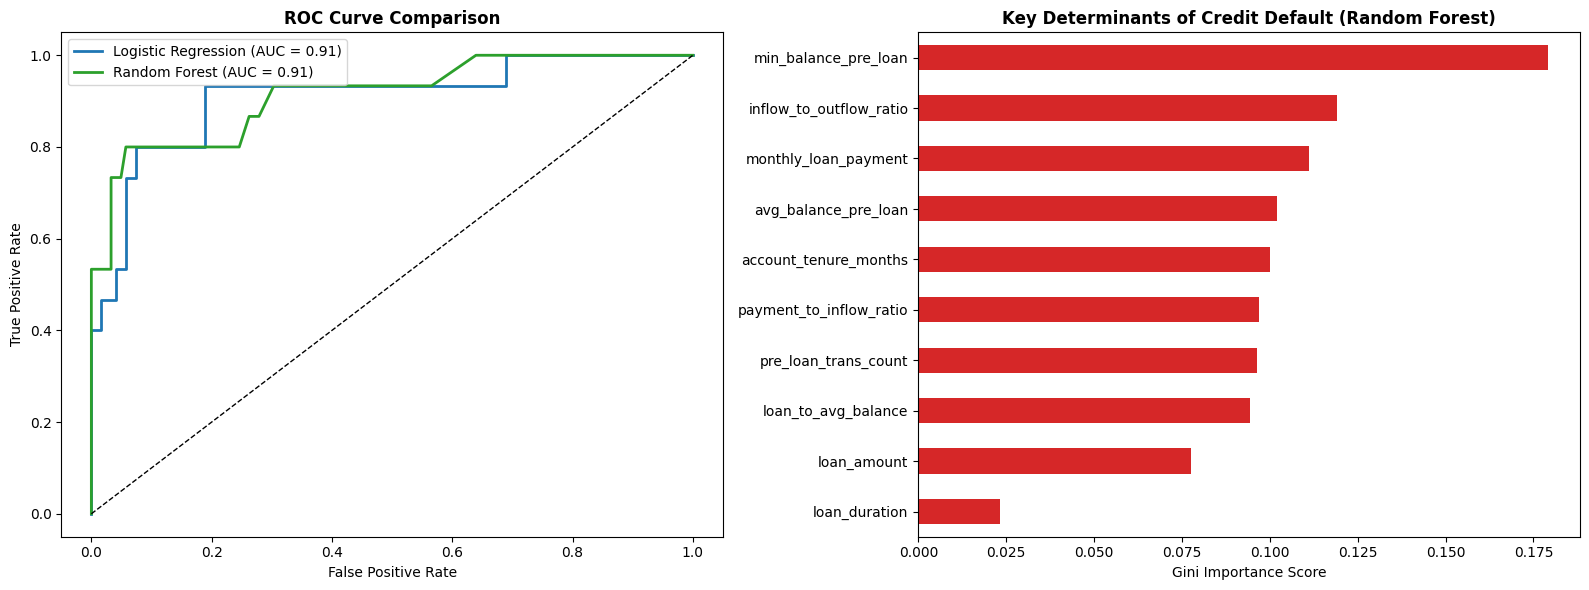

In [11]:
# ==============================================================================
# 2. MACHINE LEARNING PIPELINE: LOGISTIC REGRESSION & RANDOM FOREST
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix

# Select features for default prediction model
feature_cols = [
    'loan_amount', 'loan_duration', 'monthly_loan_payment',
    'account_tenure_months', 'pre_loan_trans_count', 'avg_balance_pre_loan',
    'min_balance_pre_loan', 'payment_to_inflow_ratio', 'loan_to_avg_balance',
    'inflow_to_outflow_ratio'
]

X = df_features[feature_cols].fillna(0)
y = df_features['is_default']

# Train-Test Split (80/20 Stratified to preserve 11% default ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression (Balanced class weight for interpretable scorecard)
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_log = log_reg.predict(X_test_scaled)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]

# Model 2: Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate ROC-AUC Scores
auc_log = roc_auc_score(y_test, y_prob_log)
auc_rf = roc_auc_score(y_test, y_prob_rf)

print("=" * 60)
print(f"📊 MODEL EVALUATION RESULTS")
print(f"• Logistic Regression ROC-AUC : {auc_log:.4f}")
print(f"• Random Forest ROC-AUC       : {auc_rf:.4f}")
print("=" * 60)
print("\n--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_log, target_names=['Non-Default (0)', 'Default (1)']))

# Plot ROC Curves & Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. ROC Curves (Plotting on axes[0])
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

axes[0].plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {auc_log:.2f})', color='#1f77b4', lw=2)
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})', color='#2ca02c', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)  # Fixed syntax: 50% random chance baseline
axes[0].set_title('ROC Curve Comparison', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# B. Random Forest Feature Importances (Plotting on axes[1])
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='#d62728')
axes[1].set_title('Key Determinants of Credit Default (Random Forest)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gini Importance Score')

plt.tight_layout()
plt.show()


In [12]:
# ==============================================================================
# 3. ATTACH PROBABILITY OF DEFAULT (PD) & EXPORT TO GOOGLE DRIVE / SQLITE
# ==============================================================================
# Calculate Probability of Default (PD) for all loans
df_features['probability_of_default'] = rf_model.predict_proba(X)[:, 1]

# Assign Risk Rating Categories
df_features['risk_category'] = pd.cut(
    df_features['probability_of_default'],
    bins=[-0.01, 0.25, 0.50, 0.75, 1.0],
    labels=['Low Risk', 'Moderate Risk', 'High Risk', 'Critical Risk']
)

# Export cleaned feature table with risk scores to Google Drive CSV
export_path = os.path.join(DATA_DIR, 'Loan_Default_Risk_Scored.csv')
df_features.to_csv(export_path, index=False)

print(f"✅ Scored dataset exported to '{export_path}'!")
display(df_features['risk_category'].value_counts())


✅ Scored dataset exported to '/content/drive/MyDrive/Capstone_Project/Loan_Default_Risk_Scored.csv'!


,count
risk_category,
Low Risk,607
High Risk,39
Critical Risk,30
Moderate Risk,6
